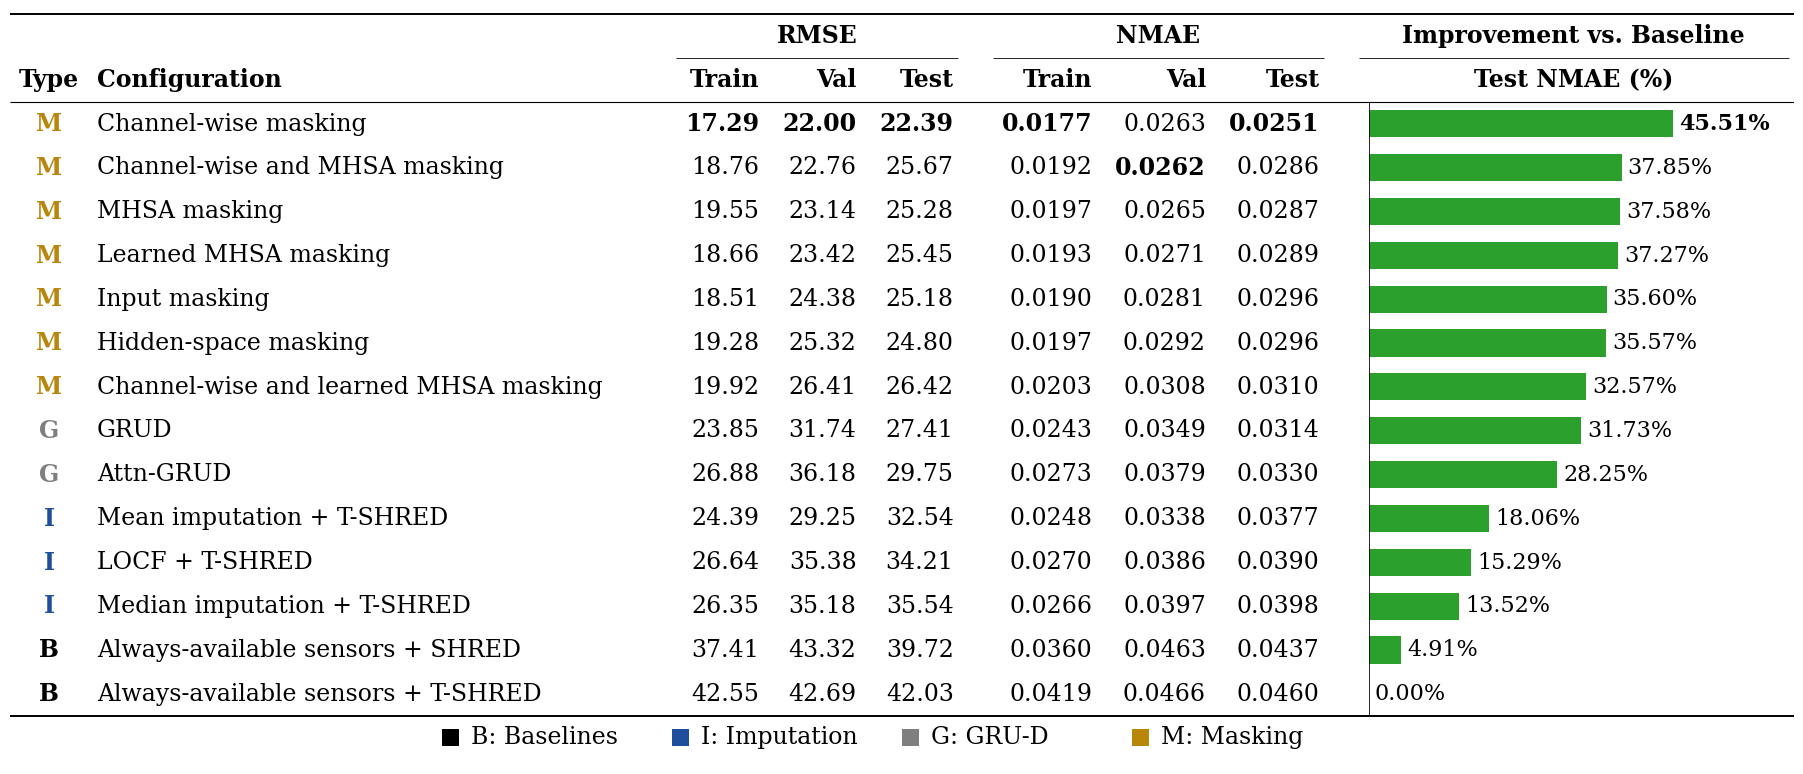

In [2]:
"""Summary table of reconstruction metrics (RMSE / NMAE) per model.

Columns: aggregated RMSE and NMAE ("Unify all"), each with Train / Val / Test,
plus a bar showing the percentage improvement in test NMAE relative to the worst model.
RMSE is computed as the square root of the MSE stored in the JSON.
"""
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle

# --------------------------------------------------------------------------- #
# Configuration
# --------------------------------------------------------------------------- #
METRICS_PATH = "results_df/reconstruction_metrics_all_models.json"
OUT_STEM = "SWE_3_table"
SPLITS = ("train", "val", "test")
SPLIT_LABELS = ("Train", "Val", "Test")
FONT = 17
PAD = 0.09          # cell inner padding (inches)
GAP_W = 0.25        # spacing between column groups
BAR_W = 4.4         # width of the bar column

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

C_BAR = "#2ca02c"
GROUPS = {  # model-name digit -> (letter, label, color)
    "0": ("B", "Baselines", "#000000"),
    "1": ("I", "Imputation", "#1F4E9C"),
    "2": ("G", "GRU-D", "#7F7F7F"),
    "3": ("M", "Masking", "#B8860B"),
}
MODEL_RENAME = {
    "T0A": "Always-available sensors + SHRED",
    "T0B": "Always-available sensors + T-SHRED",
    "T1A": "Median imputation + T-SHRED",
    "T1B": "Mean imputation + T-SHRED",
    "T1C": "LOCF + T-SHRED",
    "T2A": "GRUD",
    "T2B": "Attn-GRUD",
    "T3A": "Input masking",
    "T3B": "Channel-wise masking",
    "T3C": "Hidden-space masking",
    "T3D": "MHSA masking",
    "T3E": "Channel-wise and MHSA masking",
    "T3F": "Learned MHSA masking",
    "T3G": "Channel-wise and learned MHSA masking",
}

# (displayed title, key in the JSON, df column suffix, number format, transform)
NUM_GROUPS = [
    ("RMSE", "mse", "rmse", ".2f", np.sqrt),   # RMSE = sqrt(MSE)
    ("NMAE", "nmae", "nmae", ".4f", lambda x: x),
]


# --------------------------------------------------------------------------- #
# Data
# --------------------------------------------------------------------------- #
def load_dataframe(path):
    """Read the JSON and return a DataFrame sorted by test NMAE."""
    with open(path, encoding="utf-8") as f:
        data = json.load(f)

    rows = []
    for model, splits in data.items():
        row = {"model": model, "group": model[1]}
        for s in SPLITS:
            agg = splits[s]["Unify all"]
            for _, key, suffix, _, transform in NUM_GROUPS:
                row[f"{s}-{suffix}"] = float(transform(agg[key]))
        rows.append(row)

    df = pd.DataFrame(rows).sort_values("test-nmae", kind="stable", ignore_index=True)
    df["name"] = df["model"].map(MODEL_RENAME).fillna(df["model"])
    worst = df["test-nmae"].max()
    df["impr"] = (worst - df["test-nmae"]) / worst * 100
    return df


# --------------------------------------------------------------------------- #
# Layout
# --------------------------------------------------------------------------- #
class TextMeasurer:
    """Measure text widths (in inches) using a single temporary figure."""

    def __init__(self):
        self.fig = plt.figure()
        self.renderer = self.fig.canvas.get_renderer()

    def width(self, texts, fontsize=FONT, weight="normal"):
        widths = []
        for t in texts:
            artist = self.fig.text(0, 0, t, fontsize=fontsize, fontweight=weight)
            widths.append(artist.get_window_extent(self.renderer).width)
            artist.remove()
        return max(widths) / self.fig.dpi

    def close(self):
        plt.close(self.fig)


def compute_layout(df, tm):
    """Return column widths/positions and a map column -> (metric, format)."""
    widths = [tm.width(["Type"], weight="bold") + 2 * PAD,
              tm.width(list(df["name"]) + ["Configuration"], weight="bold") + 2 * PAD + 0.1]
    col_map, group_cols = {}, []

    for _, _, suffix, fmt, _ in NUM_GROUPS:
        cols = [f"{s}-{suffix}" for s in SPLITS]
        texts = [f"{v:{fmt}}" for c in cols for v in df[c]] + list(SPLIT_LABELS)
        w = tm.width(texts, weight="bold") + 2 * PAD + 0.05   # bold = worst case
        idxs = list(range(len(widths), len(widths) + 3))
        group_cols.append(idxs)
        col_map.update({i: (c, fmt) for i, c in zip(idxs, cols)})
        widths += [w] * 3 + [GAP_W]

    widths.append(BAR_W)
    xs = np.concatenate([[0], np.cumsum(widths)[:-1]])
    return widths, xs, group_cols, col_map


# --------------------------------------------------------------------------- #
# Drawing
# --------------------------------------------------------------------------- #
def draw_table(df):
    tm = TextMeasurer()
    widths, xs, group_cols, col_map = compute_layout(df, tm)
    BAR = len(widths) - 1
    total_w = float(sum(widths))
    label_w = tm.width(["100.00%"], fontsize=FONT - 1, weight="bold") + 0.15
    tm.close()

    best = df[[c for c, _ in col_map.values()]].min()
    best_impr = df["impr"].max()

    row_h = 0.28 * FONT / 11
    n_rows, header_rows, legend_rows = len(df), 2, 1.0
    fig_h = (n_rows + header_rows + legend_rows + 0.2) * row_h + 0.1
    fig = plt.figure(figsize=(total_w, fig_h))
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(0, total_w)
    ax.set_ylim(n_rows + header_rows + legend_rows + 0.1, -0.1)
    ax.axis("off")

    def put(col, row, text, ha="left", **kw):
        x = {"left": xs[col] + PAD,
             "right": xs[col] + widths[col] - PAD,
             "center": xs[col] + widths[col] / 2}[ha]
        ax.text(x, row + 0.5, text, ha=ha, va="center", fontsize=FONT, **kw)

    def hline(x0, x1, y, lw):
        ax.hlines(y, x0, x1, color="black", lw=lw)

    def span(c0, c1, row, label):
        x0, x1 = xs[c0], xs[c1] + widths[c1]
        ax.text((x0 + x1) / 2, row + 0.5, label, ha="center", va="center",
                fontsize=FONT, fontweight="bold")
        hline(x0 + 0.05, x1 - 0.05, row + 1, 0.6)

    # ---- header ----
    for (title, _, _, _, _), idxs in zip(NUM_GROUPS, group_cols):
        span(idxs[0], idxs[-1], 0, title)
    span(BAR, BAR, 0, "Improvement vs. Baseline")
    put(0, 1, "Type", ha="center", fontweight="bold")
    put(1, 1, "Configuration", fontweight="bold")
    for idxs in group_cols:
        for c, label in zip(idxs, SPLIT_LABELS):
            put(c, 1, label, ha="right", fontweight="bold")
    put(BAR, 1, "Test NMAE (%)", ha="center", fontweight="bold")

    # ---- bar scale ----
    bx0 = xs[BAR] + 0.15
    usable = widths[BAR] - 0.15 - label_w
    vmin, vmax = min(df["impr"].min(), 0.0), max(best_impr, 1e-9)
    scale = usable / (vmax - vmin)
    zero_x = bx0 - vmin * scale
    bar_h = 0.62

    # ---- body ----
    for r, row in enumerate(df.itertuples(index=False)):
        y = r + header_rows
        letter, _, color = GROUPS.get(str(row.group), ("?", "", "black"))
        put(0, y, letter, ha="center", color=color, fontweight="bold")
        put(1, y, row.name)
        for c, (metric, fmt) in col_map.items():
            val = df.at[r, metric]
            put(c, y, f"{val:{fmt}}", ha="right",
                fontweight="bold" if val == best[metric] else "normal")

        v = row.impr
        w = v * scale
        ax.add_patch(Rectangle((min(zero_x, zero_x + w), y + 0.5 - bar_h / 2),
                               abs(w), bar_h, facecolor=C_BAR, edgecolor="none"))
        sign = 1 if v >= 0 else -1
        ax.text(zero_x + w + sign * 0.06, y + 0.5, f"{v:.2f}%",
                ha="left" if v >= 0 else "right", va="center", fontsize=FONT - 1,
                fontweight="bold" if np.isclose(v, best_impr) else "normal")

    ax.vlines(zero_x, header_rows, n_rows + header_rows, color="black", lw=0.6)
    hline(0, total_w, 0, 1.4)
    hline(0, total_w, header_rows, 0.8)
    hline(0, total_w, n_rows + header_rows, 1.4)

    # ---- legend ----
    ly = n_rows + header_rows + legend_rows / 2
    sq, sq_h, entry_w = 0.17, 0.17 / row_h, 2.3
    x_start = (total_w - entry_w * len(GROUPS)) / 2
    for i, (letter, label, color) in enumerate(GROUPS.values()):
        x = x_start + i * entry_w
        ax.add_patch(Rectangle((x, ly - sq_h / 2), sq, sq_h, facecolor=color, edgecolor="none"))
        ax.text(x + sq + 0.12, ly, f"{letter}: {label}", ha="left", va="center", fontsize=FONT)

    return fig


def main():
    df = load_dataframe(METRICS_PATH)
    fig = draw_table(df)
    fig.savefig(f"{OUT_STEM}.png", dpi=500, bbox_inches="tight", pad_inches=0.03)
    plt.show()


if __name__ == "__main__":
    main()